In [6]:
# Load the reproducible gallery–probe protocol

from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.datasets import fetch_lfw_people

random_seed = 42

lfw = fetch_lfw_people(
    min_faces_per_person=5,
    color=True,
    resize=1.0,
    download_if_missing=True
)

images = lfw.images
labels = lfw.target
identity_names = lfw.target_names

data_directory = Path(
    "/content/drive/MyDrive/Colab Notebooks/face_degradation/data"
)

split_path = data_directory / "lfw_gallery_probe_split.csv"
gallery_probe_split = pd.read_csv(split_path)

gallery_metadata = gallery_probe_split[
    gallery_probe_split["split"] == "gallery"
].copy()

probe_metadata = gallery_probe_split[
    gallery_probe_split["split"] == "probe"
].copy()

gallery_indices = gallery_metadata["image_index"].to_numpy()
probe_indices = probe_metadata["image_index"].to_numpy()

gallery_images = images[gallery_indices]
probe_images = images[probe_indices]

print(f"Gallery tensor shape: {gallery_images.shape}")
print(f"Probe tensor shape: {probe_images.shape}")
print(f"Gallery identities: {gallery_metadata['identity_id'].nunique()}")
print(f"Probe identities: {probe_metadata['identity_id'].nunique()}")

Gallery tensor shape: (1269, 125, 94, 3)
Probe tensor shape: (846, 125, 94, 3)
Gallery identities: 423
Probe identities: 423


In [7]:
# Prepare identity labels and flatten the face images

gallery_identity_ids = gallery_metadata["identity_id"].to_numpy()
probe_identity_ids = probe_metadata["identity_id"].to_numpy()

gallery_vectors = gallery_images.reshape(len(gallery_images), -1)
probe_vectors = probe_images.reshape(len(probe_images), -1)

print(f"Gallery vector shape: {gallery_vectors.shape}")
print(f"Probe vector shape: {probe_vectors.shape}")

Gallery vector shape: (1269, 35250)
Probe vector shape: (846, 35250)


In [8]:
# Normalize image vectors for cosine similarity

def l2_normalize(vectors):
    norms = np.linalg.norm(vectors, axis=1, keepdims=True)
    return vectors / np.maximum(norms, 1e-12)

gallery_vectors_normalized = l2_normalize(gallery_vectors)
probe_vectors_normalized = l2_normalize(probe_vectors)

print(
    f"Gallery vector norms: "
    f"{np.min(np.linalg.norm(gallery_vectors_normalized, axis=1)):.4f}–"
    f"{np.max(np.linalg.norm(gallery_vectors_normalized, axis=1)):.4f}"
)

print(
    f"Probe vector norms: "
    f"{np.min(np.linalg.norm(probe_vectors_normalized, axis=1)):.4f}–"
    f"{np.max(np.linalg.norm(probe_vectors_normalized, axis=1)):.4f}"
)

Gallery vector norms: 1.0000–1.0000
Probe vector norms: 1.0000–1.0000


In [9]:
# Construct one gallery template per identity

identity_ids = np.sort(gallery_metadata["identity_id"].unique())

gallery_templates = []
template_identity_ids = []

for identity_id in identity_ids:
    identity_vectors = gallery_vectors_normalized[
        gallery_identity_ids == identity_id
    ]

    identity_template = identity_vectors.mean(axis=0, keepdims=True)
    identity_template = l2_normalize(identity_template)[0]

    gallery_templates.append(identity_template)
    template_identity_ids.append(identity_id)

gallery_templates = np.vstack(gallery_templates)
template_identity_ids = np.array(template_identity_ids)

print(f"Gallery template matrix shape: {gallery_templates.shape}")
print(f"Number of identity templates: {len(template_identity_ids)}")

Gallery template matrix shape: (423, 35250)
Number of identity templates: 423


In [10]:
# Compute probe-to-gallery cosine similarities

similarity_matrix = probe_vectors_normalized @ gallery_templates.T

print(f"Similarity matrix shape: {similarity_matrix.shape}")
print(
    f"Similarity range: "
    f"{similarity_matrix.min():.4f}–{similarity_matrix.max():.4f}"
)

Similarity matrix shape: (846, 423)
Similarity range: 0.6424–0.9894


In [11]:
# Generate ranked identity predictions

ranked_template_positions = np.argsort(
    similarity_matrix,
    axis=1
)[:, ::-1]

ranked_identity_ids = template_identity_ids[ranked_template_positions]

top_1_predictions = ranked_identity_ids[:, 0]
top_5_predictions = ranked_identity_ids[:, :5]

top_1_accuracy = np.mean(
    top_1_predictions == probe_identity_ids
)

top_5_accuracy = np.mean(
    np.any(top_5_predictions == probe_identity_ids[:, None], axis=1)
)

print(f"Rank-1 accuracy: {top_1_accuracy:.4f}")
print(f"Rank-5 accuracy: {top_5_accuracy:.4f}")

Rank-1 accuracy: 0.1123
Rank-5 accuracy: 0.1974


In [12]:
# Analyze identification failure categories

true_positions = np.array([
    np.where(template_identity_ids == identity_id)[0][0]
    for identity_id in probe_identity_ids
])

true_scores = similarity_matrix[
    np.arange(len(probe_identity_ids)),
    true_positions
]

predicted_scores = similarity_matrix[
    np.arange(len(probe_identity_ids)),
    ranked_template_positions[:, 0]
]

correct_rank_1 = ranked_identity_ids[:, 0] == probe_identity_ids
correct_rank_5 = np.any(
    ranked_identity_ids[:, :5] == probe_identity_ids[:, None],
    axis=1
)

failure_analysis = pd.DataFrame({
    "probe_index": probe_indices,
    "true_identity_id": probe_identity_ids,
    "predicted_identity_id": top_1_predictions,
    "true_similarity": true_scores,
    "predicted_similarity": predicted_scores,
    "rank_1_correct": correct_rank_1,
    "rank_5_correct": correct_rank_5
})

failure_analysis["failure_type"] = np.select(
    [
        failure_analysis["rank_1_correct"],
        failure_analysis["rank_5_correct"]
    ],
    [
        "correct_rank_1",
        "correct_within_rank_5"
    ],
    default="rank_5_failure"
)

display(
    failure_analysis["failure_type"]
    .value_counts()
    .rename_axis("failure_type")
    .to_frame("count")
)

display(
    failure_analysis
    .sort_values("true_similarity")
    .head(10)
)

,count
failure_type,
rank_5_failure,679
correct_rank_1,95
correct_within_rank_5,72


,probe_index,true_identity_id,predicted_identity_id,true_similarity,predicted_similarity,rank_1_correct,rank_5_correct,failure_type
394,2464,197,141,0.767709,0.865699,False,False,rank_5_failure
558,909,279,379,0.783351,0.858708,False,False,rank_5_failure
562,1301,281,7,0.790136,0.884242,False,False,rank_5_failure
37,5077,18,234,0.797818,0.872057,False,False,rank_5_failure
46,2080,23,225,0.814331,0.938338,False,False,rank_5_failure
458,1869,229,18,0.823274,0.877401,False,False,rank_5_failure
101,1588,50,252,0.831446,0.929154,False,False,rank_5_failure
593,5763,296,141,0.833785,0.908926,False,False,rank_5_failure
524,5419,262,88,0.845094,0.903703,False,False,rank_5_failure
793,725,396,343,0.846464,0.930501,False,False,rank_5_failure


In [13]:
# Compare genuine and strongest impostor similarities

strongest_impostor_scores = []

for row_index, true_position in enumerate(true_positions):
    impostor_scores = np.delete(
        similarity_matrix[row_index],
        true_position
    )
    strongest_impostor_scores.append(impostor_scores.max())

failure_analysis["strongest_impostor_similarity"] = (
    strongest_impostor_scores
)

failure_analysis["similarity_margin"] = (
    failure_analysis["true_similarity"]
    - failure_analysis["strongest_impostor_similarity"]
)

print(
    f"Mean genuine similarity: "
    f"{failure_analysis['true_similarity'].mean():.4f}"
)

print(
    f"Mean strongest-impostor similarity: "
    f"{failure_analysis['strongest_impostor_similarity'].mean():.4f}"
)

print(
    f"Mean genuine–impostor margin: "
    f"{failure_analysis['similarity_margin'].mean():.4f}"
)

print(
    f"Negative-margin cases: "
    f"{(failure_analysis['similarity_margin'] < 0).sum()} "
    f"of {len(failure_analysis)} probes"
)

Mean genuine similarity: 0.9503
Mean strongest-impostor similarity: 0.9654
Mean genuine–impostor margin: -0.0151
Negative-margin cases: 751 of 846 probes


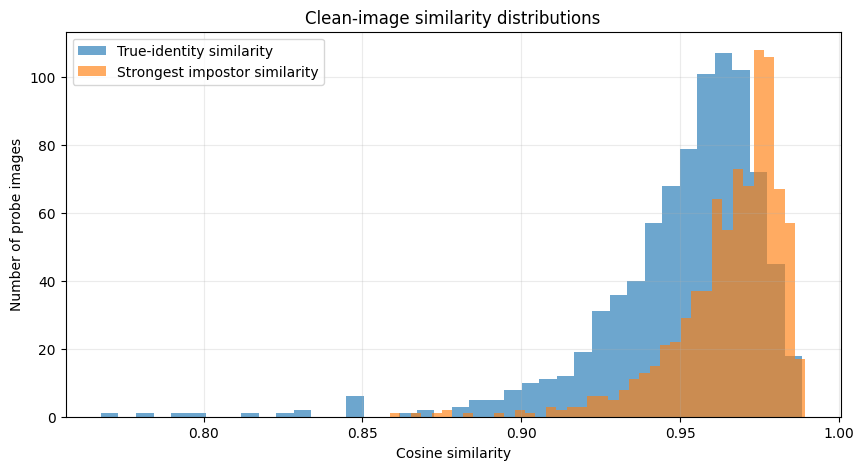

In [14]:
# Visualize the clean baseline performance

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    failure_analysis["true_similarity"],
    bins=40,
    alpha=0.65,
    label="True-identity similarity"
)

plt.hist(
    failure_analysis["strongest_impostor_similarity"],
    bins=40,
    alpha=0.65,
    label="Strongest impostor similarity"
)

plt.xlabel("Cosine similarity")
plt.ylabel("Number of probe images")
plt.title("Clean-image similarity distributions")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [15]:
# Save clean baseline results

results_directory = Path(
    "/content/drive/MyDrive/Colab Notebooks/face_degradation/results"
)

results_directory.mkdir(parents=True, exist_ok=True)

failure_analysis.to_csv(
    results_directory / "clean_pixel_baseline_results.csv",
    index=False
)

summary = pd.DataFrame({
    "metric": [
        "rank_1_accuracy",
        "rank_5_accuracy",
        "mean_true_similarity",
        "mean_strongest_impostor_similarity",
        "mean_similarity_margin"
    ],
    "value": [
        top_1_accuracy,
        top_5_accuracy,
        failure_analysis["true_similarity"].mean(),
        failure_analysis["strongest_impostor_similarity"].mean(),
        failure_analysis["similarity_margin"].mean()
    ]
})

summary.to_csv(
    results_directory / "clean_pixel_baseline_summary.csv",
    index=False
)

print(f"Results saved to: {results_directory}")

Results saved to: /content/drive/MyDrive/Colab Notebooks/face_degradation/results
